### Data Ingestion

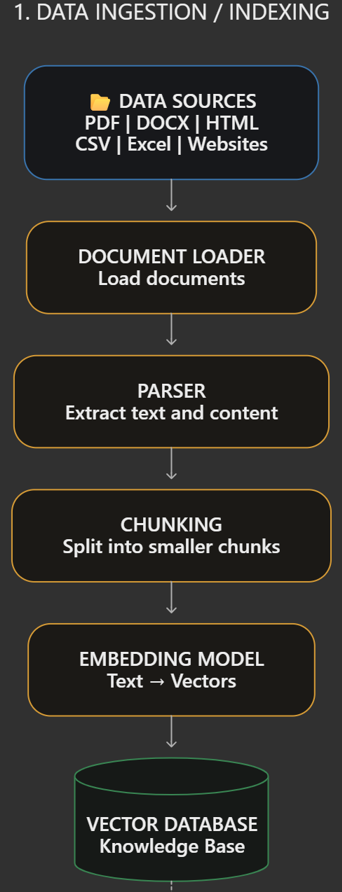

### LangChain Document Data Structure

- A **Document** represents a piece of text with associated metadata.
- It contains two main fields:
  1. **page_content:** Stores the actual text/content.
  2. **metadata:** Stores additional information like source, page number, title, etc.

### LangChain Loaders

- **Document Loaders** load data from different sources into LangChain `Document` objects.
- They convert external data into a format (document data structure) that LangChain can process.

**Common Loaders:**
- `PyPDFLoader` – Loads PDF files.
- `TextLoader` – Loads text files.
- `CSVLoader` – Loads CSV files.
- `WebBaseLoader` – Loads content from websites.
- `DirectoryLoader` – Loads multiple files from a directory.

**Common method:**
- `load()` – Loads documents.
- `lazy_load()` – Loads documents one at a time.

In [2]:
### Document Data Structure

from langchain_core.documents import Document

exampleDoc = Document(
    page_content="This is the main text content I am using to create RAG",
    metadata={
        "source":"example.txt",
        "pages":1,
        "author":"Aryan Jaiswal",
        "date_created":"2026-10-31"
    }
)

exampleDoc

Document(metadata={'source': 'example.txt', 'pages': 1, 'author': 'Aryan Jaiswal', 'date_created': '2026-10-31'}, page_content='This is the main text content I am using to create RAG')

In [7]:
### Create a simple txt file

import os
os.makedirs("../data/text_files",exist_ok=True)

sample_text = {
    "../data/text_files/ml_intro.txt":"""Machine Learning is a branch of Artificial Intelligence (AI) that enables computers to learn from data and make decisions or predictions without being explicitly programmed. It uses algorithms and statistical techniques to identify patterns in data and improve performance through experience.

    Machine Learning works by collecting data, preprocessing it, selecting a suitable algorithm, training a model, and evaluating its performance. Once trained, the model can make predictions on new, unseen data.

    There are three main types of Machine Learning:

    1. Supervised Learning:
    Supervised Learning uses labelled data, where both input and expected output are provided to the model. The model learns the relationship between inputs and outputs.
    Examples: Linear Regression, Logistic Regression, Decision Tree, Random Forest.
    Applications: House price prediction, spam detection, and student performance prediction.

    2. Unsupervised Learning:
    Unsupervised Learning uses unlabelled data. The model identifies hidden patterns, relationships, and groups without predefined outputs.
    Examples: K-Means Clustering, Hierarchical Clustering, and Principal Component Analysis (PCA).
    Applications: Customer segmentation, anomaly detection, and grouping similar documents.

    3. Reinforcement Learning:
    Reinforcement Learning is based on learning through interaction with an environment. An agent performs actions and receives rewards or penalties based on its behaviour. Its goal is to maximize the total reward.
    Examples: Q-Learning and Deep Q-Networks.
    Applications: Robotics, game playing, and autonomous vehicles.

    Some important Machine Learning algorithms include Linear Regression, Logistic Regression, Support Vector Machine (SVM), Decision Trees, Random Forest, K-Nearest Neighbors (KNN), and K-Means Clustering.

    Machine Learning has many real-world applications, such as fraud detection in banking, product recommendations in e-commerce, facial recognition, medical diagnosis, weather forecasting, speech recognition, and self-driving cars.

    The main advantages of Machine Learning are automation, improved prediction accuracy, pattern recognition, and the ability to process large amounts of data. However, it also has challenges such as insufficient training data, overfitting, underfitting, bias, and high computational requirements.

    Machine Learning plays an important role in modern technology by helping systems become smarter and make data-driven decisions.""",
    "../data/text_files/python_intro.txt":"""Python and Machine Learning

    Python is a high-level, interpreted, general-purpose programming language known for its simple syntax and readability. It is widely used in web development, automation, data science, artificial intelligence, and machine learning.

    Python provides several features that make it popular among developers. It is easy to learn, supports object-oriented programming, has a large collection of libraries, and works across different operating systems.

    Important Python Concepts:

    1. Variables and Data Types:
    Variables store data values. Python supports data types such as integers, floats, strings, booleans, lists, tuples, sets, and dictionaries.

    2. Conditional Statements:
    Conditional statements are used to make decisions in a program. Python provides if, elif, and else statements.

    3. Loops:
    Loops are used to execute a block of code repeatedly. Python provides for loops and while loops.

    4. Functions:
    Functions are reusable blocks of code that perform specific tasks. They are defined using the def keyword.

    5. Object-Oriented Programming:
    Python supports classes, objects, inheritance, polymorphism, encapsulation, and abstraction.

    6. Exception Handling:
    Exception handling manages runtime errors using try, except, else, and finally blocks.

    Important Python Libraries:

    1. NumPy:
    NumPy is used for numerical computing and working with multidimensional arrays.

    2. Pandas:
    Pandas is used for data manipulation, cleaning, and analysis. It provides DataFrame and Series data structures.

    3. Matplotlib:
    Matplotlib is used to create graphs, charts, and data visualizations.

    4. Seaborn:
    Seaborn is a visualization library built on Matplotlib. It helps create statistical graphs.

    5. Scikit-learn:
    Scikit-learn provides tools for machine learning, including classification, regression, clustering, and model evaluation.

    6. TensorFlow:
    TensorFlow is an open-source framework used to build and train deep learning models."""
}

for filepath,content in sample_text.items():
    with open(filepath,'w',encoding="utf-8") as f:
        f.write(content)

print("✅ Sample text file created!")

✅ Sample text file created!


In [13]:
### Text Loader
from langchain_community.document_loaders import TextLoader

text_loader = TextLoader("../data/text_files/ml_intro.txt",encoding="utf-8")
document = text_loader.load()
print(document)

[Document(metadata={'source': '../data/text_files/ml_intro.txt'}, page_content='Machine Learning is a branch of Artificial Intelligence (AI) that enables computers to learn from data and make decisions or predictions without being explicitly programmed. It uses algorithms and statistical techniques to identify patterns in data and improve performance through experience.\n\n    Machine Learning works by collecting data, preprocessing it, selecting a suitable algorithm, training a model, and evaluating its performance. Once trained, the model can make predictions on new, unseen data.\n\n    There are three main types of Machine Learning:\n\n    1. Supervised Learning:\n    Supervised Learning uses labelled data, where both input and expected output are provided to the model. The model learns the relationship between inputs and outputs.\n    Examples: Linear Regression, Logistic Regression, Decision Tree, Random Forest.\n    Applications: House price prediction, spam detection, and studen

In [22]:
### Directory Loader
from langchain_community.document_loaders import DirectoryLoader

## load all the text files from the directory
dir_loader= DirectoryLoader(
    "../data/text_files",
    glob='**/*.txt',  # pattern to match files
    loader_cls=TextLoader,  # loader class to use depend upon the type of files you are loading
    loader_kwargs={'encoding':'utf-8'},
    show_progress=False
)

documents = dir_loader.load()
print(len(documents))  # Total documents

for i, doc in enumerate(documents):
    print(f"\nDocument {i+1}:")
    print("Content:", doc.page_content[:200])
    print("Metadata:", doc.metadata)

2

Document 1:
Content: Machine Learning is a branch of Artificial Intelligence (AI) that enables computers to learn from data and make decisions or predictions without being explicitly programmed. It uses algorithms and sta
Metadata: {'source': '..\\data\\text_files\\ml_intro.txt'}

Document 2:
Content:     Python is a high-level, interpreted, general-purpose programming language known for its simple syntax and readability. It is widely used in web development, automation, data science, artificial in
Metadata: {'source': '..\\data\\text_files\\python_intro.txt'}


### PyPDFLoader
- Uses the `pypdf` library to load PDF files.
- Extracts text page by page.
- Each page is stored as a separate Document.

### PyMuPDFLoader
- Uses the `PyMuPDF` library to load PDF files.
- Provides fast text extraction.
- Supports page-wise loading and PDF metadata.

**Difference:** PyMuPDFLoader is generally faster, while PyPDFLoader provides basic PDF text extraction.

In [26]:
### Directory Loader
from langchain_community.document_loaders import PyPDFLoader, PyMuPDFLoader

## load all the pdf files from the directory
dir_loader= DirectoryLoader(
    "../data/pdf",
    glob='**/*.pdf',  # pattern to match files
    loader_cls=PyMuPDFLoader,  # loader class to use depend upon the type of files you are loading
    show_progress=False
)

documents = dir_loader.load()
print(len(documents))  # Total documents

for i, doc in enumerate(documents):
    print(f"\nDocument {i+1}:")
    print("Content:", doc.page_content[:])
    print("Metadata:", doc.metadata)

9

Document 1:
Content: Page 1
FORCE AND LAWS OF MOTION
Class 9 – Easy, exam-ready answers based on the questions in the uploaded pages
Note: Repeated questions from the different sections have been combined. Only the unique concepts/questions are
included, so the same answer is not repeated unnecessarily.
A. VERY SHORT ANSWER / ONE-TO-TWO LINE QUESTIONS
1. What is force?
Answer: Force is a push or a pull that can change the state of rest or motion of an object, or change its shape.
2. What are the main effects of a force?
Answer: A force can start or stop motion, change the speed or direction of motion, or change the shape of an
object.
3. What is momentum? Give its SI unit.
Answer: Momentum is the quantity of motion possessed by a body. Momentum = mass x velocity. Its SI unit is
kg m/s.
4. What is the momentum of a body at rest?
Answer: It is zero because its velocity is zero. p = mv = m x 0 = 0.
5. Is momentum a scalar or vector quantity?
Answer: Momentum is a vector quantity becaus